<img style="float: right; height: 120px; margin: 20px 0 10px 20px;" src="attachment:euclid_logo.png" alt="Euclid Consortium logo" />
<img style="float: right; height: 100px; margin: 30px 0 10px 20px;" src="attachment:ELSAlogo.png" alt="ELSA logo" />


# Galaxy physical properties at a chosen redshift from Euclid DR1: additional queries and checks

<br>

Copyright (c) Micol Bolzonella, Andrea Enia, Will Hartley, Giulia Papini, 2026.

This file is subject to the terms and conditions defined in file `LICENSE.txt`, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file `LICENSE.txt`.

**Last modified:** 2026-10-31

**Notebook summary**

This notebook complements `PP_at_z.ipynb`, which shows how to re-evaluate the physical properties (PPs) of galaxies at a chosen redshift. Please read that notebook first: it introduces the method, the catalogues and the terminology (see its glossary). Here you will learn how to:

1. Retrieve the PHZ physical-parameters catalogue for a list of objects selected in the MER photometric catalogue (Section 1)
2. Compare the SPE spectroscopic redshifts with the PHZ photometric redshifts (Section 2)
3. Explore the archive tables and their columns (Section 3)
4. Check the range of the quantities stored in the PHZ reference sample (Section 4)

Section 2 uses the files saved by `PP_at_z.ipynb`. 

**Running the notebook:**

* This notebook has **read-only permissions**. To save your changes, save it to a different location, for example your workspace.
* The functions used here are in the Python module **euclid_pp_tools.py** (v1.2), except the three archive query functions, defined in the notebook; type `help(function_name)` to read their description.
* The notebook is intended to be run with the **EUCLID-TOOLS kernel**. It has been tested in the **IDR** archive environment.


**Version:**

* v1.2: first version, with the appendices of `PP_at_z.ipynb`.

***

In [1]:
import io
import os
import re
import sys
import time
import getpass
import logging
import contextlib

import numpy as np
from astroquery import log as aq_log
from astroquery.esa.euclid.core import EuclidClass
from IPython.display import display

## Configuration

In [2]:
# Folder containing euclid_pp_tools.py
shared_utilities_path = "/media/user/euclid-contributed-jupyter-notebooks/Physical_properties/"

# Folder with the outputs of PP_at_z.ipynb, also used for the outputs of this notebook
output_folder = "/media/user/example_notebook_outputs/"

# Archive environment and schema of the catalogue tables
env = "PDR"
SCHEMA = "dr1"

# Survey: 'DEEP' or 'WIDE'
SURVEY = "DEEP" 

# Section 1: tile used to select objects in the MER catalogue (101... = Deep, 102... = Wide)
TILE_INDEX = 101834632       # E.g. 101834632, 102015162

# Files saved by PP_at_z.ipynb (used in Section 2)
spe_file = 'example_spe.parquet'
pp_file = 'example_pp.parquet'

# Table names for each survey (without the schema)
TABLE_NAMES = {
    "DEEP": {"mer":         "mer_catalogue_deep_survey",
             "pp":          "phz_physical_parameters_deep_survey",
             "spe":         "spectro_z_spe_galaxy_candidates_deep",
             "spe_quality": "spectro_z_spe_quality_deep"},
    "WIDE": {"mer":         "mer_catalogue_wide_survey",
             "pp":          "phz_physical_parameters_wide",
             "spe":         "spectro_z_spe_galaxy_candidates_wide_survey",
             "spe_quality": "spectro_z_spe_quality_wide_survey"},
}

# --- Derived settings (no need to edit) ---
tables = {key: f"{SCHEMA}.{name}" for key, name in TABLE_NAMES[SURVEY].items()}
os.makedirs(output_folder, exist_ok=True)

for key, name in tables.items():
    print(f"  {key:12s} -> {name}")

  mer          -> dr1.mer_catalogue_deep_survey
  pp           -> dr1.phz_physical_parameters_deep_survey
  spe          -> dr1.spectro_z_spe_galaxy_candidates_deep
  spe_quality  -> dr1.spectro_z_spe_quality_deep


In [3]:
if shared_utilities_path not in sys.path:
    sys.path.append(shared_utilities_path)

from euclid_pp_tools import (fix_nn_columns, merge_catalogs, read_catalog, write_catalog,
                             first_entry_per_object, scatter_zszp_1plusz,
                             diagnostic_check_all_params)

## Logging in

Log in **once**. For security reasons the login expires after a while: the query functions defined below detect this case (HTTP 401 / 403 errors), log in again automatically with `relogin` and repeat the query once; any other error is shown as it is. To log in again by hand, re-run this cell. Other login options are described in the [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) documentation.

In [4]:
Euclid = EuclidClass(environment=env)

user = input("Enter your user name: ")  # Alternatively, set your user name here: user = ''
password = getpass.getpass(prompt="Enter your password: ")
Euclid.login(user=user, password=password, verbose=False)

relogin = lambda: Euclid.login(user=user, password=password, verbose=False)    # used only if the login expires
QUERY_OPTIONS = dict(relogin=relogin)

Enter your user name:  pcruzgam
Enter your password:  ········


INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


## Archive query functions

The three functions used to query the archive are defined here (all the other functions are in `euclid_pp_tools.py`):

| Function | What it does |
|---|---|
| `get_query_results` | Launches an ADQL query on the archive, prints the runtime and returns the result as a table |
| `is_auth_error` | Tells whether an archive error is due to a missing or expired login |
| `call_with_relogin` | Calls an archive function; only if the login has expired, logs in again and retries once |

Type `help(function_name)` to read their full description.

In [5]:
def get_query_results(query, name='query', n_rows=3, relogin=None):
    """
    Launch an asynchronous ADQL query on the Euclid archive, print the runtime
    and display the first rows of the result.

    It requires the archive object `Euclid`, already logged in (see the login cell).
    A newline is added at the end of the query, so that a '--' comment on its last
    line cannot comment out what the archive appends to the query.

    Parameters
    ----------
    query : str
        The ADQL query.
    name : str, optional
        Name of the job as it will appear in the archive (default is 'query').
    n_rows : int, optional
        Number of rows to display; 0 to display none (default is 3).
    relogin : callable, optional
        Function without arguments that logs in again, used only if the login
        has expired (default is None: errors are never retried).

    Returns
    -------
    astropy.table.Table
        The result of the query.
    """
    start = time.time()
    job = call_with_relogin(Euclid.launch_job_async, query.rstrip() + '\n', verbose=False, name=name,
                            relogin=relogin)
    res = call_with_relogin(job.get_results, relogin=relogin)
    print(f'* Output table contains {len(res):,} rows')
    print(f'* Total runtime: {time.time() - start:3.1f} seconds')
    if n_rows:
        print(f'* Displaying first {n_rows} rows: ')
        display(res[0:n_rows])
    return res


# Texts of the archive errors that mean "not logged in / session expired". The last one is the
# message logged by Euclid.launch_job_async for an expired login: the archive gives no reason
# for the HTTP error, so the message ends with "HTTP error:" followed by nothing.
AUTH_ERROR_PATTERNS = (r'Error\s+40[13]\b', r'unauthori[sz]ed', r'not\s+authenticated', r'authentication',
                       r'not\s+logged', r'login\s+required', r'session\s+(has\s+)?expired',
                       r'credentials\s+expiration', r'HTTP\s+error:\s*$')


def is_auth_error(error):
    """
    Tell whether an archive error is due to a missing or expired login.

    Parameters
    ----------
    error : Exception or str
        Exception raised by an astroquery call, or the error message logged
        by astroquery.

    Returns
    -------
    bool
        True for HTTP 401 / 403 errors and for messages about authentication
        (see AUTH_ERROR_PATTERNS).
    """
    status = getattr(getattr(error, 'response', None), 'status_code', None)
    if status in (401, 403):
        return True
    return any(re.search(p, str(error), re.IGNORECASE | re.MULTILINE) for p in AUTH_ERROR_PATTERNS)


def call_with_relogin(func, *args, relogin=None, **kwargs):
    """
    Call an archive function; only if the login has expired, log in again and
    repeat the call once.

    The Euclid archive functions of astroquery do not always raise an exception
    when a request fails: some of them (e.g. launch_job_async) log the error and
    return None. Both cases are detected: errors raised, and errors logged by
    astroquery during the call. The long HTML error page that astroquery prints
    for an expired login is hidden.

    Parameters
    ----------
    func : callable
        The archive function to call, e.g. Euclid.launch_job_async or
        Euclid.load_table.
    *args, **kwargs
        Arguments passed to `func`.
    relogin : callable, optional
        Function without arguments that logs in again (the `relogin` defined in
        the login cell). If None, errors are never retried.

    Returns
    -------
    object
        Whatever `func` returns.

    Raises
    ------
    RuntimeError
        If the request fails for any other reason than an expired login, or if
        it still fails after logging in again.
    """
    for attempt in (1, 2):
        error, printed = None, io.StringIO()
        with aq_log.log_to_list() as records, contextlib.redirect_stdout(printed):
            try:
                result = func(*args, **kwargs)
            except Exception as err:
                result, error = None, err
        messages = [r.getMessage() for r in records if r.levelno >= logging.ERROR]
        if error is None and (result is not None or not messages):
            print(printed.getvalue(), end='')
            return result
        reason = error if error is not None else messages[-1]
        if attempt == 1 and relogin is not None and is_auth_error(reason):
            print('⚠️ The login has expired: logging in again and repeating the request...')
            relogin()
            continue
        print(printed.getvalue(), end='')
        text = str(reason)
        if len(text) > 800:
            text = f'{text[:300]} [...] {text[-400:]}'
        raise RuntimeError(f'The archive request failed: {text}')

## 1. PHZ catalogue for a list of objects

First, objects are selected in the MER photometric catalogue (here, all the objects of one tile). Then the list of their `object_id` is uploaded to the archive as a temporary table (`tap_upload.id_list`), which exists only for that query, and joined with the PHZ table. This works for lists of any length, e.g. the more than 100 000 objects of a Wide tile, or ids from your own catalogue. Writing the ids in the query with `WHERE object_id IN (...)` works only for short lists.

In [6]:
query = f"""SELECT object_id, right_ascension, declination, flux_detection_total, vis_det, tile_index
            FROM {tables['mer']}
            WHERE tile_index = {TILE_INDEX} AND spurious_flag = 0
            """

mer_results_table = get_query_results(query, 'MER-query', **QUERY_OPTIONS)

INFO: Query finished. [astroquery.utils.tap.core]
* Output table contains 45,273 rows
* Total runtime: 1.6 seconds
* Displaying first 3 rows: 


object_id,right_ascension,declination,flux_detection_total,vis_det,tile_index
NA,deg,deg,uJy,NA,
int64,float64,float64,float64,int16,int64
2696214630661275751,269.621463040781,66.12757511678392,0.4083815813064575,1,101834632
2700048964661283093,270.0048964044859,66.12830939397264,0.0646657794713974,1,101834632
2699356418661242231,269.93564186698325,66.12422316176021,34.20828628540039,1,101834632


In [7]:
id_table = mer_results_table[['object_id']] 

query = f"""SELECT pp.object_id, pp.phz_pdf_nn_id, pp.phz_pdf_nn_scale, pp.phz_pdf_nn_weight,
            pp.phz_pp_median_redshift, pp.phz_pp_median_stellarmass, pp.phz_pp_median_sfr,
            pp.quality_flag, pp.phys_param_flags
            FROM {tables['pp']} AS pp
            JOIN tap_upload.id_list AS ids
              ON pp.object_id = ids.object_id
            """

job = call_with_relogin(Euclid.launch_job_async, query, verbose=False, name='PP-list-query',
                        upload_resource=id_table, upload_table_name='id_list', **QUERY_OPTIONS)
pp_list_table = fix_nn_columns(call_with_relogin(job.get_results, **QUERY_OPTIONS))
print(f"{len(pp_list_table)} rows")

INFO: Query finished. [astroquery.utils.tap.core]
phz_pdf_nn_id: numeric (int64, shape (30,))
phz_pdf_nn_weight: numeric (float64, shape (30,))
phz_pdf_nn_scale: numeric (float64, shape (30,))
45273 rows


Join the two tables and save the result:

In [8]:
mer_pp_table = merge_catalogs(mer_results_table, pp_list_table)

write_catalog(mer_pp_table, output_folder + 'example_mer_pp.parquet')
mer_pp_table[0:3]

✅ Successfully saved catalog to: /media/user/example_notebook_outputs/example_mer_pp.parquet


object_id,right_ascension,declination,flux_detection_total,vis_det,tile_index,phz_pdf_nn_id,phz_pdf_nn_scale,phz_pdf_nn_weight,phz_pp_median_redshift,phz_pp_median_stellarmass,phz_pp_median_sfr,quality_flag,phys_param_flags
NA,deg,deg,uJy,NA,,,NA,NA,NA,NA,NA,NA,NA
int64,float64,float64,float64,int16,int64,int64[30],float64[30],float64[30],float64,float64,float64,float64,float64
2695178604661355192,269.51786048812033,66.13551923734863,26.527286529541016,1,101834632,173801 .. 628141,2.150344133377075 .. 0.32329118251800537,0.000202848925255239 .. 0.00019905410590581596,0.41600000858306885,10.173986434936523,0.6359290480613708,1.0,1.0
2695183214663677443,269.51832147837115,66.36774432017464,1.710152268409729,1,101834632,50152 .. 617857,0.6001102924346924 .. 2.8571860790252686,4.6784477859903266e-36 .. 5.097317459305794e-33,1.4819999933242798,9.407706260681152,1.4118337631225586,0.0,0.0
2695184026663683218,269.51840266740163,66.36832181232135,0.06508735567331314,1,101834632,127069 .. 622222,0.5012671947479248 .. 0.5677441358566284,0.01751348003745079 .. 7.566886116235037e-18,2.0179998874664307,8.22176742553711,-0.07630258798599243,0.0,0.0


## 2. Spectroscopic versus photometric redshifts

Comparison between the SPE spectroscopic redshifts and the PHZ photometric redshifts (median of the redshift PDF) of the objects retrieved in `PP_at_z.ipynb`, with the usual statistics: bias $\langle\Delta z/(1+z)\rangle$, NMAD (normalised median absolute deviation) and outlier fraction $\eta$, with outliers defined by $|z_\mathrm{p} - z_\mathrm{s}|/(1+z_\mathrm{s}) > 0.15$. Only the first SPE solution of each object is used.

With the example selection of `PP_at_z.ipynb` (SPE probability > 0.1) many spectroscopic redshifts are not reliable, which inflates the outlier fraction: use the high-probability selection for meaningful statistics.

bias = -0.0028  NMAD = 0.0776  sigma = 0.0542  outliers = 29.12%


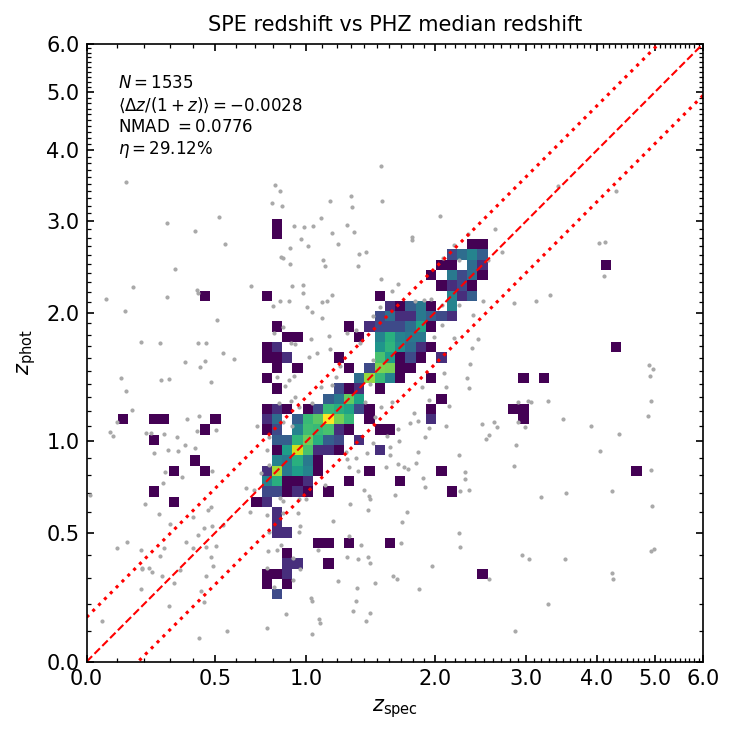

In [9]:
spe_table = first_entry_per_object(read_catalog(output_folder + spe_file))
pp_table = read_catalog(output_folder + pp_file)
zcat = merge_catalogs(pp_table, spe_table)

scatter_zszp_1plusz(zcat['spe_z'], zcat['phz_pp_median_redshift'], bins=60,
                    title='SPE redshift vs PHZ median redshift')

For a sparse sample, a scatter plot can be clearer: `scatter_zszp_1plusz(..., use_density=False, point_size=5)`. The redshift range and the outlier threshold can be changed with `zmin`, `zmax` and `out_limit`.

## 3. The archive tables

The tables available in the archive, and the description of the columns of one of them (here the PHZ physical-parameters table; any name from the list can be used).

In [10]:
archive_tables = call_with_relogin(Euclid.load_tables, only_names=True, include_shared_tables=True, **QUERY_OPTIONS)
print(f"{len(archive_tables)} tables")
for table in archive_tables:
    print(table.get_qualified_name())

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
200 tables
dr1.mer_catalogue_deep_mode
dr1.mer_catalogue_deep_mode_photometry
dr1.mer_cutouts_deep_mode
dr1.mer_morphology_deep_mode
dr1.mer_catalogue_deep_survey
dr1.mer_catalogue_deep_survey_photometry
dr1.mer_cutouts_deep_survey
dr1.mer_morphology_deep_survey
dr1.mer_catalogue_deep_visits
dr1.mer_cutouts_deep_visits
dr1.mer_morphology_deep_visits
dr1.mer_catalogue_wide_mode
dr1.mer_cutouts_wide_mode
dr1.mer_morphology_wide_mode
dr1.mer_catalogue_wide_survey
dr1.mer_cutouts_wide_survey
dr1.mer_morphology_wide_survey
dr1.phz_classification_deep_mode
dr1.phz_nir_physical_parameters_deep_mode
dr1.phz_photo_z_deep_mode
dr1.phz_physical_parameters_deep_mode
dr1.phz_qso_physical_parameters_deep_mode
dr1.phz_star_template_deep_mode
dr1.phz_classification_deep_survey
dr1.phz_nir_physical_parameters_deep_survey
dr1.phz_photo_z_deep_survey
dr1.phz_p

In [11]:
table = call_with_relogin(Euclid.load_table, tables['pp'], **QUERY_OPTIONS)
for column in table.columns:
    print(f"{column.name:40s} {str(column.unit or ''):12s} {column.description or ''}")

basic_download_data_oid                               
calblock_id_list                                      
data_set_release                                      
data_set_release_part1                                
data_set_release_part2                                
data_set_release_part3                                
imf                                      NA           IMF
object_id                                NA           Unique ID of the object in the survey, as set by MER
patch_id_list                                         
phys_param_flags                         NA           A 64 bit integer containing the flags of the physical parameters processing (TBD)
phz_pdf_nn_id                            NA           A vector containing the neighbor id
phz_pdf_nn_scale                         NA           A vector containing the neighbor scale
phz_pdf_nn_weight                        NA           A vector containing the neighbor weight 
phz_pp_68_av                        

## 4. The PHZ reference sample

The minimum and maximum of every quantity stored in the files of the reference sample, for the survey set in the Configuration cell: redshift, PPs and absolute magnitudes of the 50 realizations of each reference galaxy (see Section 1 of `PP_at_z.ipynb`). The whole files are read, so this takes a while.

In [12]:
diagnostic_check_all_params(SURVEY)   # 'WIDE' / 'DEEP'


galaxy_pp_ref_DR1_deep_1.npy (200000 galaxies)
Column                 |          Min |          Max
REDSHIFT               |       0.0020 |      10.0000
POSTERIORLOG           | -2906014464.0000 |          inf
AV                     |       0.0000 |       5.3089
RED_CURVE_INDEX        |       0.0000 |       1.0000
IMF                    |       0.0000 |       0.0000
LOGU_IONISATION        |      -3.9999 |      -2.0000
MASSFORMED             |       1.0876 |      14.3974
MB                     |     -27.0860 |       3.1777
MFUV                   |     -23.7812 |      13.9788
MH                     |     -31.9513 |      -0.9269
MI                     |     -30.1897 |       0.3202
MJ                     |     -31.4103 |      -0.5402
MKs                    |     -32.0906 |      -0.9069
MNUV                   |     -24.2514 |       8.8881
MR                     |     -29.2889 |       0.9758
MU                     |     -25.4311 |       5.0311
MV                     |     -28.2326 |       1